# Paper 18: Execution policy

v2 re-targets **every name every session** (`daily_to_target`). Diagnostics say that prints about **30 tiny fills a day**. Most of that is share drift, not a new FCF list. This paper asks whether a drift band or a minimum ticket cuts that churn without changing the NAV path.

Change only `execution`. Brain, overlay, construction, and screens stay on v2. Each trial is one knob:

1. **On-signal** — trade only on a new fundamentals snapshot, a switch flip, a breach, or the first session.
2. **Drift 1%** — skip a held name when `|target weight − current weight|` is below 1%. Exits still sell.
3. **Min $2,500** — skip a non-exit whose notional is below $2,500 (v2 floor is $100).
4. **Both** — 1% band and $2,500 together.

Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** on-signal, drift-1pct, min-2500, drift-1pct-min-2500.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-18-execution", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="18-execution",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545
        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


## One execution knob at a time


In [2]:
on_signal = run_book(
    "fcf-sma-v2-baseline", rd, paper="18-execution", id="on-signal",
    execution={"rebalance": "on_signal"},
)
drift_1pct = run_book(
    "fcf-sma-v2-baseline", rd, paper="18-execution", id="drift-1pct",
    execution={"drift_band": 0.01},
)
min_2500 = run_book(
    "fcf-sma-v2-baseline", rd, paper="18-execution", id="min-2500",
    execution={"min_trade": 2500.0},
)
both = run_book(
    "fcf-sma-v2-baseline", rd, paper="18-execution", id="drift-1pct-min-2500",
    execution={"drift_band": 0.01, "min_trade": 2500.0},
)

trials = [on_signal, drift_1pct, min_2500, both]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))


v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date'}
on-signal ce42ee4cf750
  {'book': 'on-signal', 'hash': 'ce42ee4cf750', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'on_signal, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_d

In [3]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
on-signal,1.0526,0.1128,0.1463,-0.2476,0.4555,0.6691,0.8512,3.2261,0.0434,0.0561,0.8032,36.0000,ce42ee4cf750
drift-1pct,1.0728,0.1144,0.1419,-0.2449,0.4671,0.6959,0.8881,2.8740,0.0387,0.0560,0.8032,36.0000,176599d42914
min-2500,1.0623,0.1136,0.1431,-0.2416,0.4699,0.6859,0.8737,3.2097,0.0432,0.0538,0.8032,36.0000,4eb6f4abe7be
drift-1pct-min-2500,1.0340,0.1113,0.1407,-0.2423,0.4592,0.6806,0.8696,2.7948,0.0376,0.0544,0.8032,36.0000,17f2f1f5f01a
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


on-signal KILLED train Calmar below both v2 baseline and SPUS
drift-1pct keep pass
min-2500 keep pass
drift-1pct-min-2500 keep pass


## Did the policy bind?

`compare` only sees NAV. Count fills, small tickets, turnover, cost, and the gap between holdings and targets. That is the quantity this paper claims to change.


In [5]:
import pandas as pd
from monterey.diagnostics.exposure import trading

rows = []
for book in [base, *trials]:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    stats = trading(nav, book.fills)
    fills = book.fills
    good = fills[fills["status"].isin(["filled", "partial"])] if fills is not None and not fills.empty else fills
    rows.append(
        {
            "book": book.spec.id,
            "fills": stats["fills"],
            "median_fills_per_day": stats["median_fills_per_day"],
            "small_fill_share": stats["small_fill_share"],
            "annual_turnover": stats["annual_turnover"],
            "costs": stats["costs"],
            "mean_n_fills": float(nav["n_fills"].mean()),
            "mean_max_gap": float(nav["max_gap"].mean()) if "max_gap" in nav else None,
            "trade_days": int((nav["n_fills"] > 0).sum()),
        }
    )
pd.DataFrame(rows).set_index("book")


,fills,median_fills_per_day,small_fill_share,annual_turnover,costs,mean_n_fills,mean_max_gap,trade_days
book,,,,,,,,
v2,48394,30.0000,0.8914,4.1653,"72,700.3545",28.6017,0.0020,1376
on-signal,12017,60.0000,0.6595,3.2261,"56,141.7462",7.1022,0.0020,185
drift-1pct,4636,1.0000,0.2645,2.8740,"50,646.6226",2.7400,0.0210,343
min-2500,5378,2.0000,0.0100,3.2097,"56,254.5291",3.1785,0.0028,942
drift-1pct-min-2500,3352,1.0000,0.0334,2.7948,"48,900.0498",1.9811,0.0166,321


## Path, not just the scorecard

Plot **NAV** and **drawdown**. Then plot **fills per day**. A good execution rule cuts tickets and leaves the wealth curve alone.


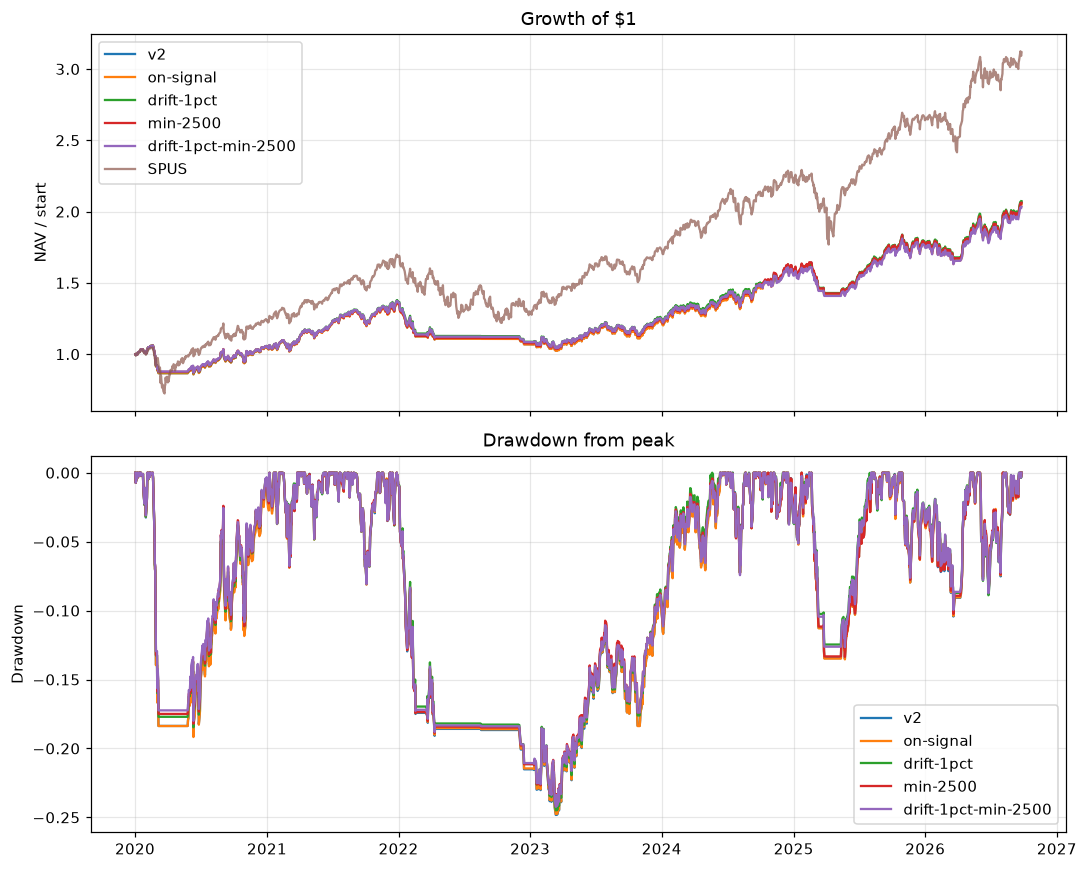

wrote figures/nav-and-drawdown.png


In [6]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)
spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    axes[0].plot(nav.index, nav / nav.iloc[0], label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)
axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].set_ylabel("NAV / start")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].set_ylabel("Drawdown")
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


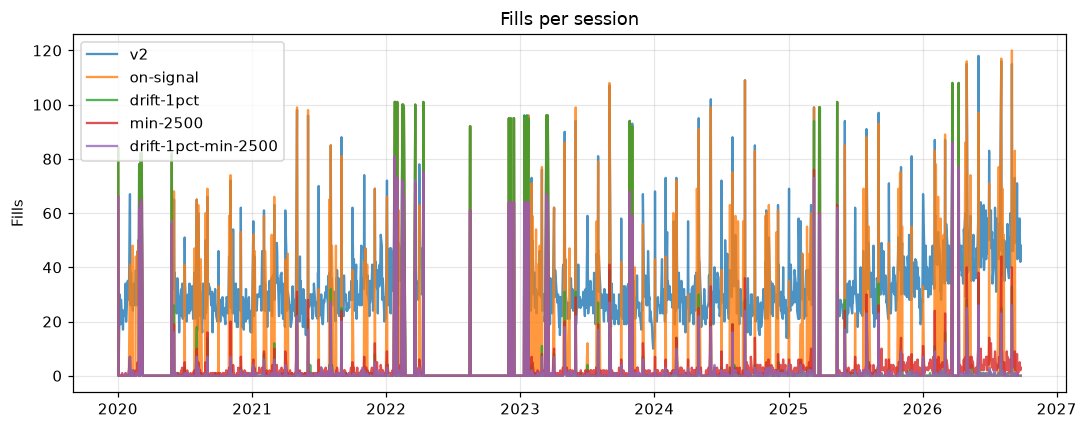

wrote figures/fills-per-day.png


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    ax.plot(nav["date"], nav["n_fills"], label=book.spec.id, alpha=0.8)
ax.set_title("Fills per session")
ax.set_ylabel("Fills")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "fills-per-day.png", dpi=140)
plt.show()
print("wrote", figures / "fills-per-day.png")


,v2,on-signal,drift-1pct,min-2500,drift-1pct-min-2500,SPUS
year,,,,,,
2020,0.0528,0.0512,0.0576,0.0568,0.0579,0.2399
2021,0.2831,0.2828,0.2916,0.2803,0.2879,0.3562
2022,-0.2080,-0.2076,-0.2042,-0.2043,-0.2036,-0.2276
2023,0.1525,0.1509,0.1569,0.1537,0.1512,0.3420
2024,0.2741,0.2736,0.2486,0.2690,0.2420,0.2649
2025,0.1250,0.1196,0.1313,0.1233,0.1276,0.1978
2026,0.1681,0.1705,0.1668,0.1647,0.1627,0.1802


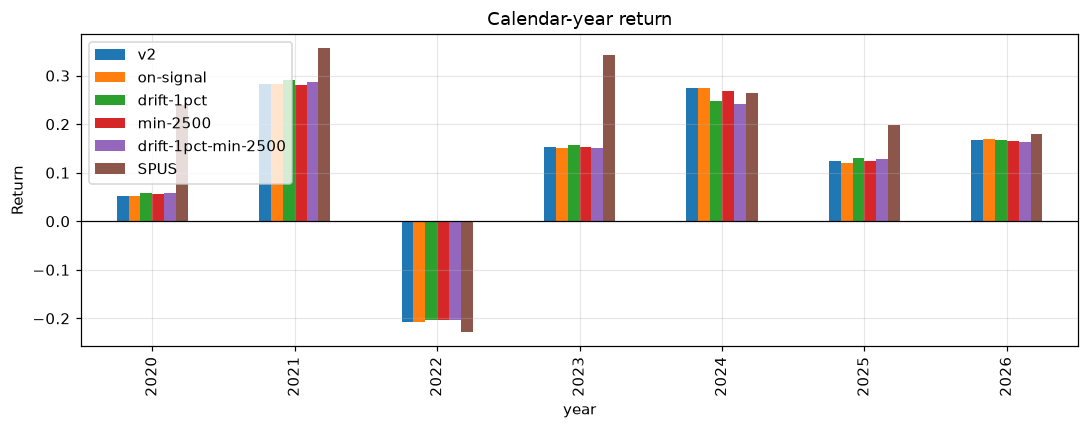

wrote figures/calendar-returns.png


In [8]:
calendar = pd.concat(
    {book.spec.id: yearly(book.nav_series())["return"] for book in books},
    axis=1,
)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_title("Calendar-year return")
ax.set_ylabel("Return")
ax.axhline(0, color="black", lw=0.8)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Conclusion

**Would we run this?** Daily re-target is not the return engine. It is an ops mess: v2 prints about **30 fills a session** and **89%** of them are under $2,000. A 1% drift band or a $2,500 minimum ticket cuts that churn and leaves the wealth curve almost unchanged. Trading only on signal days is too coarse and fails the kill rules.

**What we asked.** v2 sends every name back to target every session. This paper changed only `execution`: trade on snapshot / switch / breach only, skip names inside a 1% weight band, skip tickets under $2,500, or both. Exits still sell. Score is Calmar and max drawdown versus v2. The quantity that has to move is fills, turnover, and cost — `compare` cannot see those by itself.

**What happened.**

- The policy binds. v2: **48,394** fills, median **30** a day, annualised one-way turnover **4.17**, about $73k of 10 bp costs on $1M start. Drift 1% cuts fills to **4,636** (median 1 a day) and turnover to **2.87**. Min $2,500 cuts fills to **5,378** and almost kills the small-ticket share (1% versus 89%). Both together: **3,352** fills. On-signal: **12,017** fills on only **185** trade days — big batches, not a quiet book.
- The NAV path barely moves. v2 +106% / −24.8% / Calmar 0.46. Drift 1%: +107% / −24.5% / **0.47**. Min $2,500: +106% / −24.2% / **0.47**. Both: +103% / −24.2% / 0.46. 2022 stays about −20%. 2024 is where the band shows: drift 1% **+24.9%** versus v2 **+27.4%**.
- On-signal is **killed** (train Calmar below both v2 and SPUS). Letting weights drift until the next month-end or SMA flip is not free. Max gap stays tiny on v2 (~0.2% of weight). The 1% band lets gap rise to about **2.1%** — that is the trade: fewer tickets, a looser match to target.

**What this means for the fund.** Capacity and cost in paper 12 were dominated by the SMA on/off flips, not by monthly FCF. This paper is the other half of that honesty: the daily drip of tiny fills is real, and it is optional. A drift band or a higher min ticket is an **ops rule**, not a new alpha. It does not fix the switch, the FCF tail, or IT concentration.

**Live rule.** The scored v2 book can stay `daily_to_target` / `min_trade=100` so later papers compare against the same hash. For a desk that has to live with 30 tickets a day, promote **`drift_band=0.01`** or **`min_trade=2500`** — both pass, both cut churn, neither is a mandate upgrade. Do not switch to `on_signal`. Do not expect execution policy to raise Calmar versus SPUS.
